# Introduction to ecological data analysis
This notebook uses the completely synthetic potato-soil dataset. It shows how a community table and metadata work together.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

data = Path('../Data/Synthetic_Potato_Example')
counts = pd.read_csv(data / 'ITS_OTU_table_final.tsv', sep='\t', index_col=0)
metadata = pd.read_csv(data / 'Final_data_with_diversity_prefixed.csv').set_index('sample_id')
counts.head()

,SH_SYN001,SH_SYN002,SH_SYN003,SH_SYN004,SH_SYN005,SH_SYN006,SH_SYN007,SH_SYN008,SH_SYN009,SH_SYN010,...,SH_SYN191,SH_SYN192,SH_SYN193,SH_SYN194,SH_SYN195,SH_SYN196,SH_SYN197,SH_SYN198,SH_SYN199,SH_SYN200
sample_id,,,,,,,,,,,,,,,,,,,,,
Field_001.N1,11,40,69,166,3,159,105,44,7,54,...,0,1,1,3,19,66,0,0,10,6
Field_001.N2,1,3,6,23,0,15,5,3,2,5,...,0,0,0,0,0,5,0,0,1,0
Field_002.N1,27,103,34,208,37,31,453,36,9,72,...,0,0,0,14,5,23,0,0,11,4
Field_002.N2,5,38,10,55,9,10,127,5,1,26,...,0,0,1,3,1,6,0,0,2,0
Field_003.N1,1,4,8,22,4,5,18,5,7,8,...,0,0,0,0,1,2,0,0,6,0


## Reads and richness
Each row is a soil sample and each column is a fungal species hypothesis. Sequencing depth is the row sum. Richness is the number of taxa with at least one read.

In [2]:
total_reads = counts.sum(axis=1)
richness = (counts > 0).sum(axis=1)
summary = metadata.join(pd.DataFrame({'total_reads': total_reads, 'observed_richness': richness}))
summary[['total_reads', 'observed_richness', 'pH_KCl']].head()

,total_reads,observed_richness,pH_KCl
sample_id,,,
Field_001.N1,14748,189,5.530101
Field_001.N2,1333,151,5.512250
Field_002.N1,13017,187,6.098625
Field_002.N2,3631,181,6.290949
Field_003.N1,1013,150,6.751106


## Why depth matters
Low-depth samples often miss rare taxa, so compare depth and observed richness before interpreting richness differences.

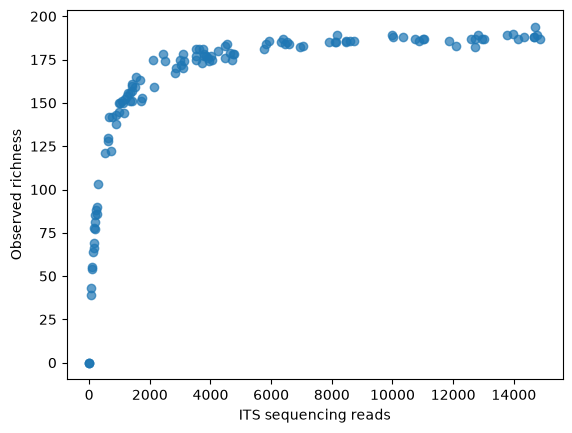

Spearman rho = 0.97, p = 3.49e-77


In [3]:
plt.scatter(summary.total_reads, summary.observed_richness, alpha=.7)
plt.xlabel('ITS sequencing reads'); plt.ylabel('Observed richness'); plt.show()
rho, p = spearmanr(summary.total_reads, summary.observed_richness)
print(f'Spearman rho = {rho:.2f}, p = {p:.3g}')

## Shannon diversity
Shannon diversity combines richness and evenness. Empty libraries are excluded because proportions are undefined.

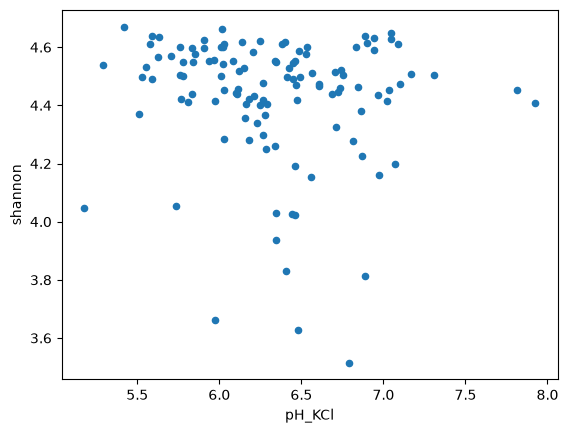

In [4]:
nonempty = counts.loc[total_reads > 0]
proportions = nonempty.div(nonempty.sum(axis=1), axis=0)
shannon = -(proportions.where(proportions > 0, 1) * proportions.where(proportions > 0, 1).apply(lambda x: x.map(__import__('math').log))).sum(axis=1)
summary.loc[shannon.index, 'shannon'] = shannon
summary[['pH_KCl', 'shannon']].dropna().plot.scatter(x='pH_KCl', y='shannon')
plt.show()

Interpret associations as teaching examples only. The synthetic README describes the deliberately simulated relationships.